# The Exponential distribution and the Plymouth Typhoid outbreak 

[Paraphrasing the CDC](https://www.cdc.gov/typhoid-fever/about/index.html), Typhoid fever is a potentially life-threatening infection caused by *Salmonella Typhi*. A related illness, paratyphoid fever, is caused by *Salmonella Paratyphi*. These infections remain an important global health problem, especially in areas with limited access to clean water and sanitation. In the United States, most cases are associated with international travel.

Typhoid is spread through the fecal–oral route, usually when food or water becomes contaminated by an infected person or carrier. Common symptoms include prolonged fever, weakness, stomach pain, headache, and loss of appetite. Prevention relies on safe food and water practices, good sanitation and hand hygiene, and vaccination for people traveling to areas where typhoid is common.

**A 32 page account of a massive outbreak of typhoid fever in Plymouth PA is available at the National Library of Medicine here** https://collections.nlm.nih.gov/bookviewer?PID=nlm:nlmuid-9801178-bk. 


## Time to recovery and incubation times

You can always use practice on computing probabilities from an estimated density, and learning what you can say about this estimated density in a public health context. This is good for you: like brocolli. 

**Question 01** Please read, in total, the 32 page account of the Plymouth Outbreak linked above. 
In this account there was data from 11 patients about when they were exposed to the pathogen and when symptoms onset. Please create a dataset below with 11 rows---one for each patient---and columns that are "time of exposure" and "time of symptom onset". In those two columns i want you **not** to enter times but instead the sentence that was used to describe the date like "ill nearly as week by April 22". 

## Probability densities that describe "Time to event"

Time to event is an incredibly frequent way to study a subject, and most often you see this in clinical applications.
For example, a randomized clinical trial is conducted, patients are enrolled, and the time from enrollment until some prespecified adverse event is record. 
You might collect a dataset like this 

| Patient | Enrollment | Adverse event date | Time until event (days) | 
|---------|---------|---------|---------|
1 | May 4 | July 4 | 61 | 
2 | June 1 | July 3 | 32|
3 | January 2 | March 4 | 61|  
4 | February 5 | July 5 | 150| 

How should we describe a dataset like this? 

A common method for describing a time to event dataset is with the exponential distribution. 
A random variable $Y~\sim \text{Exponential}(\lambda)$ has a exponential distribution with parameter $\lambda$ if

\begin{align}
    f_{Y}(y) &= \lambda e^{-\lambda y} \\ 
    P(Y<y) &= e^{-\lambda y} \\ 
    \text{supp}(Y) &= [0,\infty) \\  
    \mathbb{E}(Y) &= \frac{1}{\lambda} ; \; \mathbb{V}(Y) = \frac{1}{\lambda^{2}} 
\end{align}

The parameter $\lambda$ describes the average number of events per time unit. This could be number of fatal heart attacks per year, number of cars passing an intersection per hour, or number of individuals who clear an infection per week. 

The density for the exponential look like this 

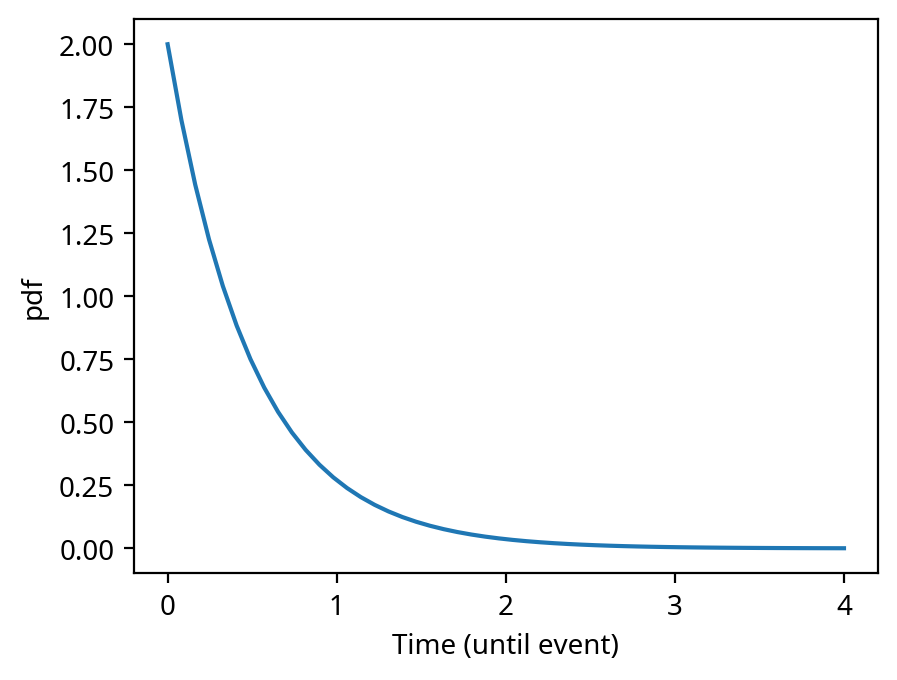

In [18]:
import scipy.stats
import numpy as np 
import matplotlib.pyplot as plt 

lam = 2 
support = np.linspace(0,4,50)
pdf = scipy.stats.expon(scale=1./lam,loc=0).pdf(support)

fig,ax = plt.subplots()
ax.plot( support, pdf )
ax.set_ylabel("pdf")
ax.set_xlabel("Time (until event)")
plt.show()

Lets see how this type of setup can help us characterize the incubation time for the popualation exposed to Typhoid. 

### Inference on $\lambda$

The typical setup assumes that we know the incubation time (rougly the time from exposure to symptom onset) for all Plymouth subjects. 
Lets assume this is the case. Then we can assign a random variable to every subject $(Y_{1}, Y_{2}, \cdots, Y_{11})$ , and we can assume all eleven random variables have the same distribution $\text{Exponential}(\lambda)$. 

If we know the incubation time for everyone then we can derive an estimator for $\lambda$ using the maximum likelihood approach. 
In other words, we look at the function 

\begin{align}
P(Y_{1}=y_{1}, Y_{2}=y_{2}, \cdots, Y_{11}=y_{11}) &=  P(Y_{1}=y_{1}) \cdot P(Y_{2}=y_{2}) \cdot P(Y_{3}=y_{3}) \cdots P(Y_{11}=y_{11}) \\ 
&= \lambda e^{\lambda y_{1}} \cdot \lambda e^{\lambda y_{2}} \cdot \lambda e^{\lambda y_{3}} \cdots \lambda e^{\lambda y_{11}} \\
f(\lambda) &= \lambda^{11} e^{ - \lambda \sum_{i=1}^{11} y_{i}  }  \\ 
\end{align}

Maximizing this functionm above sort of sucks. 
You can do it, but you wont have much fun.
Fortunately, the solution that maximizes $f$ above is also the same solution that maximizes $\log(f)$. 
Lets take the log 

\begin{align}
 \log \left[ f(\lambda) \right] &= 11 \log(\lambda) - \lambda \sum_{i=1}^{11} y_{i}  \\ 
\end{align}

The derivative is 

\begin{align}
 \log \left[ f(\lambda) \right]' &= 11\frac{1}{\lambda}  -  \sum_{i=1}^{11} y_{i}  \\ 
\end{align}

and setting this to zero (ie where is the derivative zero) means that our estimate for $\lambda$ is 

\begin{align}
    \lambda &= \frac{11}{\sum_{i=1}^{11} y_{i}} 
\end{align}

for our 11 data points. For $n$ data points the estmator is 

\begin{align}
    \lambda &= \frac{n}{\sum_{i=1}^{n} y_{i}} 
\end{align}

To recap, the MLE steps that we went through were:   
1. Assume every data point was generated by a random variable with a specific form 
2. Form the probability of this dataset being generated $P(Y_{1},Y_{2},\cdots)$
3. Most often, assume indepdendence so that $P(Y_{1})P(Y_{2})\cdots$
4. Recognize that (3) is a function of your parameter values 
5. Attempt to optimize for that parameter value. 

**Question 02** Please make a best guess for the time until symptom onset for your dataset above. 
I reocgnize that these reports are linguistic and not quantiative. Thats ok. I am looking for an approach, rationale for your approach, and then an estimate of $\lambda$. In addition, please evaluate whether that $\lambda$ value seems reasonable or not? 

**Question 03** Please (1) code-up a histogram of the 11 estimated incubation times; (2) code-up the estimated probability density function for your estimated exponential density. (3) Compare the empricial and theoretical densities. Does our model seem reasonable or not really (and why)? 

**Question 04** Statistical estimates depend on a data-generating process being sufficiently random to justify the use of random varibales like we have done here. In that 32 page account, was there any information in there to suggest this was or was not a random process by which the author collected individuals? What can you say about a statistical analysis like this? 